In [ ]:
import pandas as pd

df = pd.read_csv("D:\\projects\\creditcard_fraud\\notebooks\\data\\creditcard_1.csv")

In [15]:
df.shape

(283726, 31)

In [16]:
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [17]:
df.isnull().sum().sum()

0

In [18]:
duplicates = df.duplicated().sum()

print(duplicates)

2804


In [19]:
df[["Amount", "Time"]].describe()

,Amount,Time
count,283726.000000,283726.000000
mean,88.472687,14.045646
std,250.399437,5.834817
min,0.000000,0.000000
25%,5.600000,10.000000
50%,22.000000,15.000000
75%,77.510000,19.000000
max,25691.160000,23.000000


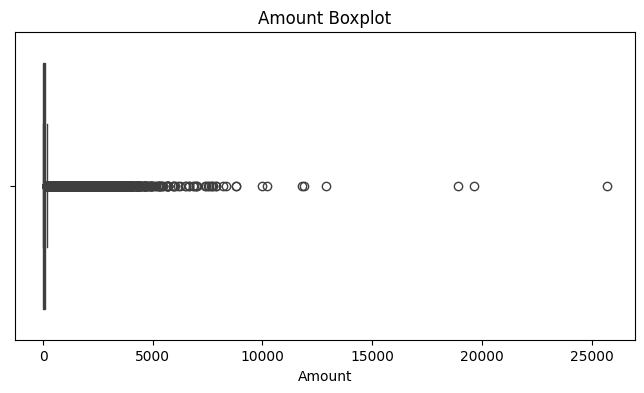

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,4))
sns.boxplot(x=df["Amount"])
plt.title("Amount Boxplot")
plt.savefig("../reports/eda/amount_boxplot.png", dpi=300)
plt.show()


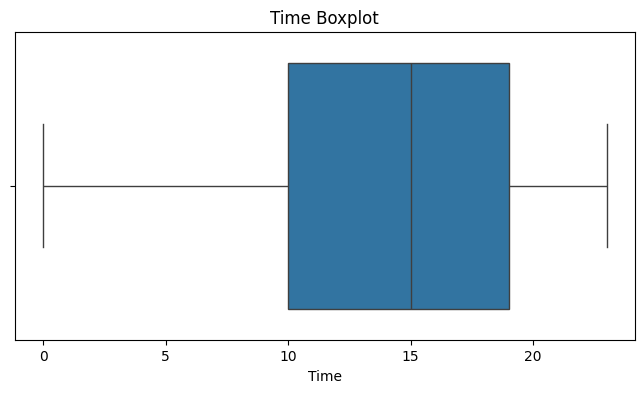

In [22]:
plt.figure(figsize=(8,4))
sns.boxplot(x=df["Time"])
plt.title("Time Boxplot")
plt.savefig("../reports/eda/time_boxplot.png", dpi=300)
plt.show()

In [23]:
Q1 = df["Amount"].quantile(0.25)
Q3 = df["Amount"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df["Amount"] < lower) | (df["Amount"] > upper)]

print(len(outliers))

31685


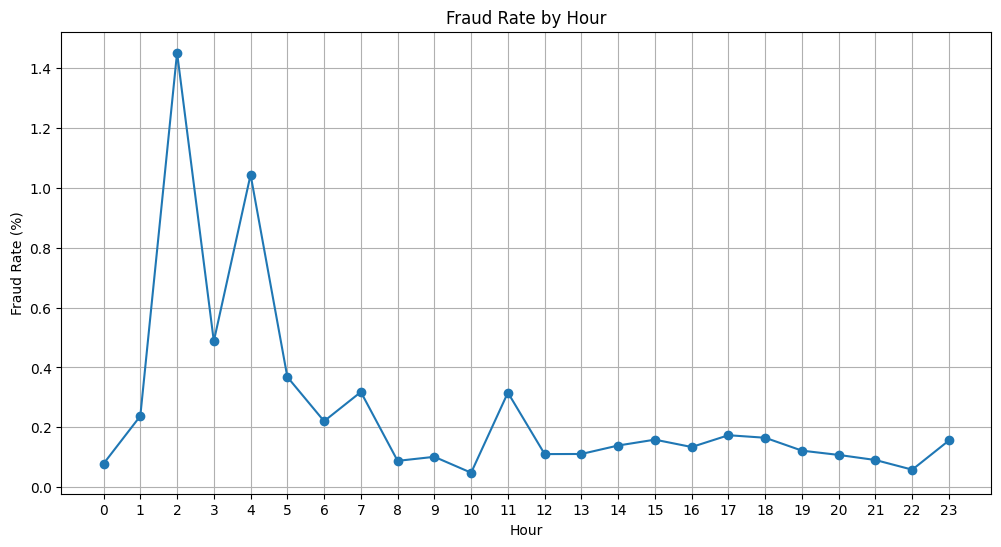

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df["Hour"] = (df["Time"] // 3600) % 24
total_txns = df.groupby("Hour").size()
fraud_txns = df[df["Class"] == 1].groupby("Hour").size()
fraud_rate = (fraud_txns / total_txns) * 100
fraud_rate = fraud_rate.fillna(0)
plt.figure(figsize=(12,6))

plt.plot(
    fraud_rate.index,
    fraud_rate.values,
    marker='o'
)

plt.title("Fraud Rate by Hour")
plt.xlabel("Hour")
plt.ylabel("Fraud Rate (%)")

plt.xticks(range(24))
plt.grid(True)
plt.savefig("../reports/eda/Fraud Rate by Hour.png", dpi=300)
plt.show()